# Selección de segmentos para EP2 (ampliación del dataset)

Continuación de `00_exploracion_bucket_waymo.ipynb`. Allí se eligieron **4
segmentos de contraste** para el EDA de EP1; acá se arma la **muestra ampliada**
con la que se entrenarán los modelos de EP2. El 00 queda intacto como
evidencia de la etapa anterior.

Está pensado para **Google Colab** (usa `google.colab.auth` y `gsutil` contra
`gs://waymo_open_dataset_v_2_0_1/`). Se ejecuta una sola vez, de arriba a abajo.

## Qué hace

1. **Inventario** de los 798 segmentos desde el componente `stats` (clima,
   momento del día, ubicación) y, **sin descargar `lidar_box`**, también
   número de frames, número de detecciones y conteo por clase.
2. **Disponibilidad**: qué segmentos tienen archivo de `lidar_box` y de
   `camera_to_lidar_box_association`, con su tamaño.
3. **Diagnóstico de los 5 segmentos `rain`**: en EP1 se dijo que 4 tenían "0
   asociaciones", pero la función `contar_asociaciones` devolvía 0 tanto si el
   archivo no existía como si estaba vacío. Acá se distinguen los casos
   (ausente / vacía / no cruza con `lidar_box`) y se decide el uso de cada uno.
4. **Muestreo estratificado** por `time_of_day` × `location`, con semilla fija,
   verificando cada candidato y **registrando cada reemplazo**.
5. **Resumen** de la muestra frente a la población de 798 segmentos.
6. **Exportación**: lista para el YAML de Kedro, tablas para el README y un
   `.tar.gz` con la misma estructura de carpetas del proyecto.

## Decisiones de diseño (justificación para el informe)

- **`weather` no se usará como predictor en EP2.** Se muestrea por
  `time_of_day` y `location`; `weather` solo interviene para **incluir los
  segmentos de lluvia** (prueba de estrés y clustering) y documentar el sesgo.
  Esto reemplaza la frase de la conclusión del notebook 00 que sugería incluir
  `weather` como variable del modelo.
- **Los segmentos de EP1 se evalúan primero** dentro de su estrato (ya los
  conocemos), pero si no pasan los criterios se descartan igual y queda
  registrado.
- **Se exige etiquetado denso.** En EP1 se vio que algunos segmentos tienen
  ~1 asociación por frame entre decenas de objetos: ahí `tiene_camara = 0` es
  falta de etiqueta y no ausencia de cámara. Se rechazan los segmentos donde,
  *dentro de los frames que sí tienen etiquetas*, menos de
  `MIN_TASA_ETIQUETADA` % de las detecciones tiene cámara.
- **Los segmentos de lluvia sin etiquetas confiables se conservan solo para
  clustering** (no necesita target) y no entran al entrenamiento supervisado.
- **Cada rechazo queda registrado** con su motivo. Es la evidencia de que el
  sesgo de selección está controlado.

## Sección 1 — Acceso y configuración

Se autentica con la misma cuenta de Google que aceptó los términos del Waymo
Open Dataset. Todos los criterios de selección están en **una sola celda de
parámetros**, para poder ajustarlos sin tocar el resto del código.

In [ ]:
from google.colab import auth

auth.authenticate_user()
print("Autenticado. Esta cuenta debe tener aceptados los terminos de Waymo Open Dataset en waymo.com/open.")

Autenticado. Esta cuenta debe tener aceptados los terminos de Waymo Open Dataset en waymo.com/open.


In [ ]:
import glob
import os
import re
import shutil
import subprocess

import numpy as np
import pandas as pd

# --- Bucket y carpetas -------------------------------------------------------
BUCKET = "gs://waymo_open_dataset_v_2_0_1/training"
N_SEGMENTOS_ESPERADO = 798

RUTA_STATS = "/content/waymo_stats"
RAIZ_SALIDA = "/content/waymo_ep2"                         # replica data/01_raw/ del proyecto Kedro
RUTA_LIDAR = f"{RAIZ_SALIDA}/waymo/lidar_box"
RUTA_ASOC = f"{RAIZ_SALIDA}/waymo/camera_to_lidar_box_association"
RUTA_META = f"{RAIZ_SALIDA}/waymo/metadatos_ep2"
RUTA_STAGING = "/content/waymo_ep2_staging"                # descargas de prueba (incluye candidatos rechazados)

for ruta in [RUTA_STATS, RUTA_LIDAR, RUTA_ASOC, RUTA_META,
             f"{RUTA_STAGING}/lidar_box", f"{RUTA_STAGING}/camera_to_lidar_box_association"]:
    os.makedirs(ruta, exist_ok=True)

# --- Reproducibilidad --------------------------------------------------------
SEMILLA = 42

# --- Criterios de "segmento utilizable" --------------------------------------
MIN_FRAMES = 190                       # un segmento completo trae ~200 frames (20 s a 10 Hz)
MIN_ASOC_FILAS = 50                    # minimo de filas en camera_to_lidar_box_association
MIN_POSITIVOS = 30                     # minimo de detecciones con tiene_camara=1 tras el cruce
MIN_TASA_ETIQUETADA = 5.5              # % minimo de detecciones con camara DENTRO de los frames con etiquetas
                                       # (separa segmentos con ~1 etiqueta por frame de los densamente etiquetados)
PERCENTILES_DETECCIONES = (2.5, 97.5)  # se excluyen segmentos con n_detecciones extremo

# --- Cuotas del muestreo estratificado (time_of_day, location) ---------------
# Cuotas ampliadas respecto de la primera version: el criterio de etiquetado denso descarta
# ~1/3 de los candidatos, asi que se piden mas para llegar a ~40 segmentos supervisados.
CUOTAS = {
    ("Day", "location_sf"): 7,
    ("Day", "location_phx"): 7,
    ("Day", "location_other"): 4,
    ("Night", "location_sf"): 5,
    ("Night", "location_phx"): 6,
    ("Night", "location_other"): 3,
    ("Dawn/Dusk", "location_sf"): 4,
    ("Dawn/Dusk", "location_phx"): 5,
    ("Dawn/Dusk", "location_other"): 2,
}

# --- Segmentos de EP1 (se fuerzan dentro de la muestra) ----------------------
SEGMENTOS_EP1 = [
    "10023947602400723454_1120_000_1140_000",   # sunny / Day / SF
    "10206293520369375008_2796_800_2816_800",   # sunny / Night / PHX
    "11017034898130016754_697_830_717_830",     # sunny / Dawn-Dusk / other
    "6791933003490312185_2607_000_2627_000",    # rain  / Night / PHX (unico rain con asociaciones; segun stats es Night, no Dawn-Dusk)
]
SEGMENTO_LLUVIA_EP1 = "6791933003490312185_2607_000_2627_000"

# --- Llave de cruce lidar_box <-> asociacion (igual que en EP1) --------------
LLAVE = ["key.segment_context_name", "key.frame_timestamp_micros", "key.laser_object_id"]

print(f"Cuota total de segmentos sin lluvia: {sum(CUOTAS.values())}")

Cuota total de segmentos sin lluvia: 43


In [ ]:
def gsutil(*args):
    # Ejecuta gsutil y devuelve su salida; si falla, muestra el error real.
    resultado = subprocess.run(["gsutil", *args], capture_output=True, text=True)
    if resultado.returncode != 0:
        raise RuntimeError(f"gsutil {' '.join(args)} fallo:\n{resultado.stderr}")
    return resultado.stdout

## Sección 2 — Inventario de los 798 segmentos

Se reutiliza el componente `stats` (≈23 KB por segmento). Además de las tres
columnas de metadatos, `stats` trae por frame los conteos de objetos LiDAR por
tipo (`lidar_object_counts.types` / `.counts`). Sumándolos se obtiene, **sin
bajar `lidar_box`**, cuántas detecciones tiene cada segmento y cuántos
`CYCLIST` / `PEDESTRIAN`. Eso permite filtrar segmentos "chicos" o con pocos
ciclistas antes de descargar nada pesado.

In [ ]:
if not glob.glob(f"{RUTA_STATS}/*.parquet"):
    gsutil("-m", "cp", f"{BUCKET}/stats/*.parquet", f"{RUTA_STATS}/")

archivos_stats = sorted(glob.glob(f"{RUTA_STATS}/*.parquet"))
print(f"Archivos de stats: {len(archivos_stats)} (esperados: {N_SEGMENTOS_ESPERADO})")

inventario = pd.concat([pd.read_parquet(f) for f in archivos_stats], ignore_index=True)
inventario["segment_id"] = inventario["key.segment_context_name"]
print(f"Inventario: {inventario.shape[0]:,} filas (una por frame), {inventario['segment_id'].nunique()} segmentos")

Archivos de stats: 798 (esperados: 798)
Inventario: 158,081 filas (una por frame), 798 segmentos


In [ ]:
def encontrar_columna(df, sufijo):
    # Las columnas de stats llevan prefijo '[StatsComponent].'; se busca por sufijo.
    candidatas = [c for c in df.columns if c.endswith(sufijo)]
    if len(candidatas) != 1:
        raise KeyError(f"Se esperaba 1 columna que termine en '{sufijo}', hay {candidatas}")
    return candidatas[0]


COL_TIPOS = encontrar_columna(inventario, "lidar_object_counts.types")
COL_CUENTAS = encontrar_columna(inventario, "lidar_object_counts.counts")

# Cada celda es un array (tipos) y otro array (conteos) del mismo largo: se pasan a formato largo.
filas = []
for seg, tipos, cuentas in zip(inventario["segment_id"], inventario[COL_TIPOS], inventario[COL_CUENTAS]):
    if tipos is None or cuentas is None:
        continue
    for tipo, cuenta in zip(tipos, cuentas):
        filas.append((seg, int(tipo), int(cuenta)))
conteos_largo = pd.DataFrame(filas, columns=["segment_id", "tipo", "conteo"])

# CONTROL: confirmar que los codigos de tipo son los esperados antes de nombrarlos.
print("Codigos de tipo presentes en stats:", sorted(int(t) for t in conteos_largo["tipo"].unique()))

Codigos de tipo presentes en stats: [1, 2, 3, 4]


In [ ]:
# Codigos de tipo de objeto de Waymo: 1=VEHICLE, 2=PEDESTRIAN, 3=SIGN, 4=CYCLIST.
# Si la celda anterior muestra codigos distintos, corregir este diccionario.
TIPOS = {1: "VEHICLE", 2: "PEDESTRIAN", 3: "SIGN", 4: "CYCLIST"}

conteos = (
    conteos_largo.groupby(["segment_id", "tipo"])["conteo"].sum().unstack(fill_value=0)
    .rename(columns=TIPOS)
)
for clase in TIPOS.values():
    if clase not in conteos.columns:
        conteos[clase] = 0

COL_META = {
    "[StatsComponent].weather": "weather",
    "[StatsComponent].time_of_day": "time_of_day",
    "[StatsComponent].location": "location",
}
meta = inventario.groupby("segment_id").first()[list(COL_META)].rename(columns=COL_META)
n_frames = inventario.groupby("segment_id")["key.frame_timestamp_micros"].nunique().rename("n_frames")

tabla = meta.join(n_frames).join(conteos)
tabla["n_detecciones"] = conteos.sum(axis=1)
tabla = tabla.fillna({c: 0 for c in conteos.columns}).fillna({"n_detecciones": 0})
tabla.index.name = "segment_id"

print(f"Tabla de segmentos: {tabla.shape[0]} filas x {tabla.shape[1]} columnas")
tabla.head()

Tabla de segmentos: 798 filas x 9 columnas


,weather,time_of_day,location,n_frames,VEHICLE,PEDESTRIAN,SIGN,CYCLIST,n_detecciones
segment_id,,,,,,,,,
10017090168044687777_6380_000_6400_000,sunny,Day,location_sf,198,4337,0,2676,0,7013
10023947602400723454_1120_000_1140_000,sunny,Day,location_sf,199,7253,6640,4587,153,18633
1005081002024129653_5313_150_5333_150,sunny,Day,location_phx,199,1596,409,1070,0,3075
10061305430875486848_1080_000_1100_000,sunny,Day,location_sf,198,5563,242,1164,0,6969
10072140764565668044_4060_000_4080_000,sunny,Day,location_sf,198,12329,2248,4944,37,19558


In [ ]:
# Cuantos segmentos hay en cada combinacion: sirve para validar que las cuotas son alcanzables.
print(pd.crosstab([tabla["weather"], tabla["time_of_day"]], tabla["location"], margins=True))

tabla.reset_index().to_csv(f"{RUTA_META}/inventario_segmentos.csv", index=False)

location             location_other  location_phx  location_sf  All
weather time_of_day                                                
rain    Dawn/Dusk                 0             3            0    3
        Day                       0             0            1    1
        Night                     0             1            0    1
sunny   Dawn/Dusk                 4            38           27   69
        Day                      88           213          345  646
        Night                    13            29           36   78
All                             105           284          409  798


## Sección 3 — Disponibilidad de archivos (sin descargar los datos)

`gsutil ls -l` entrega el tamaño en bytes de cada archivo. Con eso se sabe, de
una sola vez para los 798 segmentos, **si el archivo existe** y cuánto pesa
(un archivo de asociación casi vacío pesa muy poco). Esto separa dos
situaciones que en EP1 quedaron mezcladas en un "0 asociaciones":

| Situación | Qué significa |
|---|---|
| Archivo **ausente** | No hay etiquetas de cámara publicadas para ese segmento (problema de cobertura). |
| Archivo **vacío** o casi | Existe, pero sin asociaciones. |

In [ ]:
PATRON_LS = re.compile(r"^\s*(\d+)\s+\S+\s+gs://\S+/([^/\s]+)\.parquet\s*$")


def listar_componente(componente, nombre_columna):
    # Lista un componente del bucket y devuelve segment_id + tamano en bytes.
    salida = gsutil("ls", "-l", f"{BUCKET}/{componente}/*.parquet")
    filas = []
    for linea in salida.splitlines():
        m = PATRON_LS.match(linea)
        if m:
            filas.append({"segment_id": m.group(2), nombre_columna: int(m.group(1))})
    return pd.DataFrame(filas)


listado_lidar = listar_componente("lidar_box", "lidar_bytes")
listado_asoc = listar_componente("camera_to_lidar_box_association", "asoc_bytes")

tabla = (
    tabla.reset_index()
    .merge(listado_lidar, on="segment_id", how="left")
    .merge(listado_asoc, on="segment_id", how="left")
    .set_index("segment_id")
)
tabla["lidar_existe"] = tabla["lidar_bytes"].notna()
tabla["asoc_existe"] = tabla["asoc_bytes"].notna()

print(f"lidar_box:  {tabla['lidar_existe'].sum()} de {len(tabla)} segmentos tienen archivo")
print(f"asociacion: {tabla['asoc_existe'].sum()} de {len(tabla)} segmentos tienen archivo")
print("\nSegmentos SIN archivo de asociacion, por clima:")
print(tabla.loc[~tabla["asoc_existe"], "weather"].value_counts())

lidar_box:  798 de 798 segmentos tienen archivo
asociacion: 798 de 798 segmentos tienen archivo

Segmentos SIN archivo de asociacion, por clima:
Series([], Name: count, dtype: int64)


## Sección 4 — Verificación de un segmento y diagnóstico de la lluvia

`verificar_segmento` descarga **a una carpeta de prueba** (`staging`) los
archivos de un candidato y mide: filas de asociación, filas de `lidar_box`,
detecciones que cruzan (positivos), la **densidad de etiquetas** y el motivo si
hay un problema.

**Densidad de etiquetas.** Hay segmentos con ~1 asociación por frame entre
decenas de objetos (la tasa de positivos queda en 0,4 %–3 %): en ellos el 0 de
`tiene_camara` es falta de etiqueta. La métrica es `tasa_frames_etiq` = positivos
/ detecciones *de los frames con al menos un positivo*. Se normaliza por la
cantidad de objetos de cada escena, porque una escena con 12 objetos por frame
puede tener 1,6 positivos por frame y estar bien etiquetada. En los datos de la
primera ejecución no hay un salto limpio; `MIN_TASA_ETIQUETADA = 5.5` separa los
segmentos con ≈1 etiqueta por frame en escenas cargadas del resto. Es una
decisión de criterio: conviene probar la sensibilidad (p. ej. 3,5 y 7). Solo los
segmentos aceptados se copian a la carpeta final, así los rechazados no
terminan en la entrega.

Para no bajar `lidar_box` inútilmente, en el muestreo solo se descarga si la
asociación tiene filas suficientes. En el diagnóstico de lluvia se descarga
siempre (`forzar_lidar=True`), porque un segmento sin etiquetas igual sirve
para clustering.

In [ ]:
def descargar(componente, segment_id):
    # Descarga un archivo a staging (si no esta ya) y devuelve su ruta local.
    destino = f"{RUTA_STAGING}/{componente}/{segment_id}.parquet"
    if not os.path.exists(destino):
        gsutil("cp", f"{BUCKET}/{componente}/{segment_id}.parquet", destino)
    return destino


_cache_verificacion = {}


def verificar_segmento(segment_id, forzar_lidar=False):
    # Mide un segmento candidato. Devuelve un dict con metricas y 'problema' (diagnostico factual).
    if segment_id in _cache_verificacion:
        return _cache_verificacion[segment_id]

    fila = tabla.loc[segment_id]
    r = {
        "segment_id": segment_id,
        "asoc_existe": bool(fila["asoc_existe"]), "asoc_filas": 0,
        "lidar_existe": bool(fila["lidar_existe"]), "lidar_filas": 0,
        "positivos": 0, "pct_positivos": np.nan, "problema": "",
        "frames_etiquetados": 0, "pos_por_frame_etiq": np.nan, "tasa_frames_etiq": np.nan,
    }

    asoc = None
    if r["asoc_existe"]:
        asoc = pd.read_parquet(descargar("camera_to_lidar_box_association", segment_id), columns=LLAVE)
        r["asoc_filas"] = len(asoc)
        asoc = asoc.drop_duplicates()   # una deteccion puede ser vista por mas de una camara

    problemas = []
    if not r["asoc_existe"]:
        problemas.append("asociacion ausente")
    elif r["asoc_filas"] == 0:
        problemas.append("asociacion vacia")
    if not r["lidar_existe"]:
        problemas.append("lidar_box ausente")

    asoc_suficiente = r["asoc_filas"] >= MIN_ASOC_FILAS
    if r["lidar_existe"] and (forzar_lidar or asoc_suficiente):
        lidar = pd.read_parquet(descargar("lidar_box", segment_id), columns=LLAVE)
        r["lidar_filas"] = len(lidar)
        if asoc is not None and len(asoc) > 0:
            cruce = lidar.merge(asoc.assign(tiene_camara=1), on=LLAVE, how="left")
            cruce["tiene_camara"] = cruce["tiene_camara"].fillna(0)
            r["positivos"] = int(cruce["tiene_camara"].sum())
            r["pct_positivos"] = r["positivos"] / max(len(lidar), 1) * 100
            if r["positivos"] == 0:
                problemas.append("las asociaciones no cruzan con lidar_box")
            else:
                # Densidad de etiquetas: solo se miran los frames que tienen al menos un positivo.
                por_frame = cruce.groupby("key.frame_timestamp_micros")["tiene_camara"].agg(positivos="sum", filas="count")
                etiquetados = por_frame[por_frame["positivos"] > 0]
                r["frames_etiquetados"] = len(etiquetados)
                r["pos_por_frame_etiq"] = r["positivos"] / len(etiquetados)
                r["tasa_frames_etiq"] = r["positivos"] / etiquetados["filas"].sum() * 100

    r["problema"] = "; ".join(problemas)
    _cache_verificacion[segment_id] = r
    return r


def evaluar_supervisado(r, min_positivos, min_asoc=MIN_ASOC_FILAS, min_tasa=MIN_TASA_ETIQUETADA):
    # Devuelve '' si el segmento sirve para entrenamiento supervisado, o el motivo del rechazo.
    if r["problema"]:
        return r["problema"]
    if r["asoc_filas"] < min_asoc:
        return f"pocas asociaciones ({r['asoc_filas']} < {min_asoc})"
    if r["positivos"] < min_positivos:
        return f"pocos positivos ({r['positivos']} < {min_positivos})"
    if r["tasa_frames_etiq"] < min_tasa:
        return f"etiquetado ralo ({r['tasa_frames_etiq']:.1f}% < {min_tasa}% en frames etiquetados)"
    return ""


muestra = {}   # segment_id -> {uso, estrato, motivo}


def aceptar(segment_id, uso, estrato, motivo=""):
    # Copia el segmento aceptado a la carpeta final. 'solo_clustering' no necesita asociacion.
    shutil.copy(f"{RUTA_STAGING}/lidar_box/{segment_id}.parquet", RUTA_LIDAR)
    if uso == "supervisado":
        shutil.copy(f"{RUTA_STAGING}/camera_to_lidar_box_association/{segment_id}.parquet", RUTA_ASOC)
    muestra[segment_id] = {"segment_id": segment_id, "uso": uso, "estrato": estrato, "motivo": motivo}

### Diagnóstico de los 5 segmentos `rain`

Reglas de uso (la lluvia es tan escasa que `MIN_ASOC_FILAS` y `MIN_POSITIVOS` bajan
al mínimo: 1 fila de asociación y 1 positivo; el criterio de etiquetado denso
**sí se mantiene**, porque sin él el target no significa nada):

| Resultado | Uso |
|---|---|
| Cruza con `lidar_box` y etiquetado denso | `supervisado` (prueba de estrés) |
| Con `lidar_box` pero sin etiquetas confiables (vacía, no cruza o etiquetado ralo) | `solo_clustering` |
| Sin `lidar_box` | `descartado` |

In [ ]:
def decidir_uso_lluvia(r):
    motivo = evaluar_supervisado(r, min_positivos=1, min_asoc=1)   # lluvia: umbrales minimos, pero SI exige etiquetado denso
    if motivo == "":
        return "supervisado", ""
    if r["lidar_existe"]:
        return "solo_clustering", motivo
    return "descartado", motivo


ids_lluvia = tabla.index[tabla["weather"] == "rain"].tolist()
print(f"Segmentos con lluvia en el dataset: {len(ids_lluvia)}")

diag = []
for seg in ids_lluvia:
    r = verificar_segmento(seg, forzar_lidar=True)
    uso, motivo = decidir_uso_lluvia(r)
    diag.append({
        **r,
        "time_of_day": tabla.loc[seg, "time_of_day"],
        "location": tabla.loc[seg, "location"],
        "n_frames": tabla.loc[seg, "n_frames"],
        "n_detecciones_stats": tabla.loc[seg, "n_detecciones"],
        "uso": uso, "motivo": motivo,
    })
    if uso != "descartado":
        aceptar(seg, uso, estrato="rain", motivo=motivo)

diagnostico_lluvia = pd.DataFrame(diag)
columnas_vista = ["segment_id", "time_of_day", "location", "asoc_existe", "asoc_filas",
                  "lidar_existe", "lidar_filas", "positivos", "pct_positivos",
                  "pos_por_frame_etiq", "tasa_frames_etiq", "uso", "motivo"]
diagnostico_lluvia[columnas_vista]

Segmentos con lluvia en el dataset: 5


,segment_id,time_of_day,location,asoc_existe,asoc_filas,lidar_existe,lidar_filas,positivos,pct_positivos,pos_por_frame_etiq,tasa_frames_etiq,uso,motivo
0,13830510593707564159_5575_000_5595_000,Dawn/Dusk,location_phx,True,0,True,1263,0,NaN,NaN,NaN,solo_clustering,asociacion vacia
1,16511546224219511043_6226_000_6246_000,Dawn/Dusk,location_phx,True,0,True,986,0,NaN,NaN,NaN,solo_clustering,asociacion vacia
2,2974991090366925955_4924_000_4944_000,Dawn/Dusk,location_phx,True,0,True,805,0,NaN,NaN,NaN,solo_clustering,asociacion vacia
3,3132521568089292927_2220_000_2240_000,Day,location_sf,True,0,True,1305,0,NaN,NaN,NaN,solo_clustering,asociacion vacia
4,6791933003490312185_2607_000_2627_000,Night,location_phx,True,117,True,6837,86,1.257862,1.061728,2.18607,solo_clustering,etiquetado ralo (2.2% < 5.5% en frames etiquet...


In [ ]:
# Control: el segmento de lluvia de EP1 era el unico con asociaciones (86 positivos).
fila_ep1 = diagnostico_lluvia.set_index("segment_id").loc[SEGMENTO_LLUVIA_EP1]
print(f"Segmento de lluvia de EP1 -> uso: {fila_ep1['uso']} | positivos por frame etiquetado: "
      f"{fila_ep1['pos_por_frame_etiq']:.1f} | tasa en frames etiquetados: {fila_ep1['tasa_frames_etiq']:.1f}%")
if fila_ep1["uso"] != "supervisado":
    print("Sin etiquetado denso: no sirve como prueba de estres cuantitativa; queda solo para clustering.")

print("\nResumen del diagnostico:")
print(diagnostico_lluvia["uso"].value_counts().to_string())
print("\nMotivos entre los que no sirven para supervisado:")
print(diagnostico_lluvia.loc[diagnostico_lluvia["uso"] != "supervisado", "motivo"].value_counts().to_string())

Segmento de lluvia de EP1 -> uso: solo_clustering | positivos por frame etiquetado: 1.1 | tasa en frames etiquetados: 2.2%
Sin etiquetado denso: no sirve como prueba de estres cuantitativa; queda solo para clustering.

Resumen del diagnostico:
uso
solo_clustering    5

Motivos entre los que no sirven para supervisado:
motivo
asociacion vacia                                       4
etiquetado ralo (2.2% < 5.5% en frames etiquetados)    1


### Interpretación (completar tras ejecutar)

- **"Asociación vacía"** (el archivo existe, con 0 filas): no se sabe qué
  detecciones vio la cámara; no se puede construir el target. En la primera
  ejecución fueron 4 de 5 segmentos de lluvia, pero también el 18 % de los
  segmentos soleados, así que el vacío no es exclusivo de la lluvia.
- **"Etiquetado ralo"**: hay asociaciones, pero ~1 por frame. El segmento de
  lluvia de EP1 cae acá, por lo que su tasa de positivos (1,26 %) refleja
  falta de etiquetas y **no** un efecto del clima. Hay que reescribir la
  sección 7 del README en ese punto.
- **"No cruzan con `lidar_box`"**: sería un problema de llaves; revisar antes
  de descartar.
- Los segmentos `solo_clustering` se usarán en IE7 para ver si las detecciones
  bajo lluvia forman perfiles distintos, y para comparar distribuciones
  (*data drift*) sin necesitar target.

## Sección 5 — Muestreo estratificado de segmentos sin lluvia

**Estratos:** `time_of_day` × `location`. `time_of_day` es la variable clave
porque el KPI de equidad se reformula como brecha `Day` vs `Night`.
`location` evita un modelo que solo conoce San Francisco.

**Pool elegible** (se aplica un filtro tras otro y se muestra el embudo):

1. Sin lluvia (la lluvia se trata aparte en la sección 4).
2. Existe archivo de `lidar_box` **y** de asociación.
3. Al menos `MIN_FRAMES` frames (segmento no truncado).
4. `n_detecciones` dentro de los percentiles configurados (sin extremos).

Los segmentos de EP1 entran primero en su estrato. El resto se ordena al azar
con `SEMILLA`, **por estrato**, para que cambiar una cuota no altere el
orden de los demás estratos.

In [ ]:
no_lluvia = tabla[tabla["weather"] != "rain"]
embudo = {"1. sin lluvia": len(no_lluvia)}

c = no_lluvia[no_lluvia["asoc_existe"] & no_lluvia["lidar_existe"]]
embudo["2. con asociacion y lidar_box"] = len(c)

c = c[c["n_frames"] >= MIN_FRAMES]
embudo[f"3. n_frames >= {MIN_FRAMES}"] = len(c)

bajo, alto = c["n_detecciones"].quantile([PERCENTILES_DETECCIONES[0] / 100, PERCENTILES_DETECCIONES[1] / 100])
pool = c[(c["n_detecciones"] >= bajo) & (c["n_detecciones"] <= alto)]
embudo[f"4. n_detecciones entre {bajo:,.0f} y {alto:,.0f}"] = len(pool)

print(pd.Series(embudo).to_string())

disponibles = pool.groupby(["time_of_day", "location"]).size()
comparacion = pd.DataFrame({
    "disponibles": disponibles,
    "cuota": pd.Series(CUOTAS).rename_axis(["time_of_day", "location"]),
}).fillna(0).astype(int)
comparacion["alcanzable"] = comparacion["disponibles"] >= comparacion["cuota"]
print()
print(comparacion)

1. sin lluvia                            793
2. con asociacion y lidar_box            793
3. n_frames >= 190                       786
4. n_detecciones entre 2,027 y 33,688    746

                            disponibles  cuota  alcanzable
time_of_day location                                      
Dawn/Dusk   location_other            4      2        True
            location_phx             34      5        True
            location_sf              22      4        True
Day         location_other           87      4        True
            location_phx            201      7        True
            location_sf             324      7        True
Night       location_other           12      3        True
            location_phx             27      6        True
            location_sf              35      5        True


In [ ]:
# Orden de candidatos por estrato: primero los de EP1, despues el resto mezclado con la semilla.
orden_candidatos = {}
for (tod, loc), cuota in CUOTAS.items():
    forzados = [
        s for s in SEGMENTOS_EP1
        if s in tabla.index and tabla.loc[s, "weather"] != "rain"
        and tabla.loc[s, "time_of_day"] == tod and tabla.loc[s, "location"] == loc
    ]
    ids = pool[(pool["time_of_day"] == tod) & (pool["location"] == loc)].index
    resto = sorted(set(ids) - set(forzados))
    np.random.RandomState(SEMILLA).shuffle(resto)
    orden_candidatos[(tod, loc)] = forzados + resto

print({estrato: len(lista) for estrato, lista in orden_candidatos.items()})

{('Day', 'location_sf'): 324, ('Day', 'location_phx'): 201, ('Day', 'location_other'): 87, ('Night', 'location_sf'): 35, ('Night', 'location_phx'): 27, ('Night', 'location_other'): 12, ('Dawn/Dusk', 'location_sf'): 22, ('Dawn/Dusk', 'location_phx'): 34, ('Dawn/Dusk', 'location_other'): 4}


### Verificación y reemplazos

Se recorre la lista de cada estrato hasta completar la cuota. Cada candidato se
verifica (asociaciones suficientes, cruce con `lidar_box`, mínimo de
positivos y etiquetado denso). Si falla, se registra el motivo y se pasa al siguiente **del mismo
estrato**. Esto toma unos minutos porque descarga archivos.

In [ ]:
registro = []

for (tod, loc), cuota in CUOTAS.items():
    n_ok = 0
    print(f"\n[{tod} / {loc}] cuota = {cuota}")
    for seg in orden_candidatos[(tod, loc)]:
        if n_ok >= cuota:
            break
        r = verificar_segmento(seg)
        motivo = evaluar_supervisado(r, min_positivos=MIN_POSITIVOS)
        ok = motivo == ""
        registro.append({
            "segment_id": seg, "time_of_day": tod, "location": loc,
            "es_ep1": seg in SEGMENTOS_EP1,
            "asoc_filas": r["asoc_filas"], "lidar_filas": r["lidar_filas"], "positivos": r["positivos"],
            "pos_por_frame_etiq": r["pos_por_frame_etiq"], "tasa_frames_etiq": r["tasa_frames_etiq"],
            "resultado": "seleccionado" if ok else "descartado", "motivo": motivo,
        })
        if ok:
            aceptar(seg, "supervisado", estrato=f"{tod} / {loc}")
            n_ok += 1
        print(f"  {'OK ' if ok else 'X  '} {seg}  {motivo}")
    if n_ok < cuota:
        print(f"  ATENCION: solo se completaron {n_ok} de {cuota}")

registro = pd.DataFrame(registro)
print(f"\nSegmentos aceptados en total (con lluvia): {len(muestra)}")


[Day / location_sf] cuota = 7
  OK  10023947602400723454_1120_000_1140_000  
  OK  2577669988012459365_1640_000_1660_000  
  X   17216329305659006368_4800_000_4820_000  etiquetado ralo (2.7% < 5.5% en frames etiquetados)
  X   3194871563717679715_4980_000_5000_000  etiquetado ralo (4.8% < 5.5% en frames etiquetados)
  OK  10444454289801298640_4360_000_4380_000  
  OK  15882343134097151256_4820_000_4840_000  
  X   16608525782988721413_100_000_120_000  etiquetado ralo (1.8% < 5.5% en frames etiquetados)
  OK  5835049423600303130_180_000_200_000  
  OK  1988987616835805847_3500_000_3520_000  
  X   4457475194088194008_3100_000_3120_000  etiquetado ralo (5.2% < 5.5% en frames etiquetados)
  OK  9110125340505914899_380_000_400_000  

[Day / location_phx] cuota = 7
  X   16262849101474060261_3459_585_3479_585  asociacion vacia
  OK  10964956617027590844_1584_680_1604_680  
  OK  12174529769287588121_3848_440_3868_440  
  OK  4971817041565280127_780_500_800_500  
  OK  2342300897175196823_1

In [ ]:
# Registro de candidatos rechazados: va al README como evidencia del control de calidad.
rechazados = registro[registro["resultado"] == "descartado"]
print(f"Candidatos evaluados: {len(registro)} | seleccionados: {(registro['resultado'] == 'seleccionado').sum()} | descartados: {len(rechazados)}")
rechazados

Candidatos evaluados: 91 | seleccionados: 41 | descartados: 50


,segment_id,time_of_day,location,es_ep1,asoc_filas,lidar_filas,positivos,pos_por_frame_etiq,tasa_frames_etiq,resultado,motivo
2,17216329305659006368_4800_000_4820_000,Day,location_sf,False,133,7684,34,1.000000,2.746365,descartado,etiquetado ralo (2.7% < 5.5% en frames etiquet...
3,3194871563717679715_4980_000_5000_000,Day,location_sf,False,247,5266,171,1.285714,4.781879,descartado,etiquetado ralo (4.8% < 5.5% en frames etiquet...
6,16608525782988721413_100_000_120_000,Day,location_sf,False,133,10627,112,1.000000,1.814059,descartado,etiquetado ralo (1.8% < 5.5% en frames etiquet...
9,4457475194088194008_3100_000_3120_000,Day,location_sf,False,118,8316,115,1.949153,5.187190,descartado,etiquetado ralo (5.2% < 5.5% en frames etiquet...
11,16262849101474060261_3459_585_3479_585,Day,location_phx,False,0,0,0,NaN,NaN,descartado,asociacion vacia
16,17902907331132202998_1564_000_1584_000,Day,location_phx,False,156,11697,141,1.424242,2.624721,descartado,etiquetado ralo (2.6% < 5.5% en frames etiquet...
17,14561791273891593514_2558_030_2578_030,Day,location_phx,False,78,6754,42,1.000000,3.939962,descartado,etiquetado ralo (3.9% < 5.5% en frames etiquet...
21,7940496892864900543_4783_540_4803_540,Day,location_other,False,241,11635,218,2.319149,3.830610,descartado,etiquetado ralo (3.8% < 5.5% en frames etiquet...
22,11076364019363412893_1711_000_1731_000,Day,location_other,False,0,0,0,NaN,NaN,descartado,asociacion vacia
27,6386303598440879824_1520_000_1540_000,Night,location_sf,False,0,0,0,NaN,NaN,descartado,asociacion vacia


## Sección 6 — Resumen de la muestra final

Se compara la muestra contra la población de 798 segmentos. La muestra **no
busca ser representativa** (sobrerrepresenta noche, amanecer/atardecer y
lluvia a propósito), pero esa diferencia debe quedar cuantificada para el
README y para interpretar las métricas globales.

In [ ]:
columnas_tabla = ["weather", "time_of_day", "location", "n_frames", "n_detecciones", *TIPOS.values()]
metricas = pd.DataFrame(_cache_verificacion.values())[
    ["segment_id", "asoc_filas", "lidar_filas", "positivos", "pct_positivos",
     "frames_etiquetados", "pos_por_frame_etiq", "tasa_frames_etiq"]
]

manifiesto = (
    pd.DataFrame(muestra.values())
    .merge(tabla.reset_index()[["segment_id", *columnas_tabla]], on="segment_id", how="left")
    .merge(metricas, on="segment_id", how="left")
)
manifiesto["es_ep1"] = manifiesto["segment_id"].isin(SEGMENTOS_EP1)

print(f"Segmentos en la muestra: {len(manifiesto)}")
print(manifiesto["uso"].value_counts().to_string())
print(f"\nSegmentos de EP1 incluidos: {manifiesto['es_ep1'].sum()} de {len(SEGMENTOS_EP1)}")
print(f"Detecciones LiDAR totales de la muestra: {int(manifiesto['lidar_filas'].sum()):,}")

Segmentos en la muestra: 46
uso
supervisado        41
solo_clustering     5

Segmentos de EP1 incluidos: 3 de 4
Detecciones LiDAR totales de la muestra: 500,809


In [ ]:
# Cuotas pedidas vs obtenidas (segmentos supervisados sin lluvia)
obtenido = (
    manifiesto[(manifiesto["uso"] == "supervisado") & (manifiesto["weather"] != "rain")]
    .groupby(["time_of_day", "location"]).size()
)
cumplimiento = pd.DataFrame({
    "cuota": pd.Series(CUOTAS).rename_axis(["time_of_day", "location"]),
    "obtenido": obtenido,
}).fillna(0).astype(int)
cumplimiento["faltan"] = cumplimiento["cuota"] - cumplimiento["obtenido"]
print(cumplimiento)
if (cumplimiento["faltan"] > 0).any():
    print("\nEstratos incompletos: documentarlos en el README como subrepresentados (no forzar el balance).")

                            cuota  obtenido  faltan
time_of_day location                               
Dawn/Dusk   location_other      2         2       0
            location_phx        5         5       0
            location_sf         4         4       0
Day         location_other      4         4       0
            location_phx        7         7       0
            location_sf         7         7       0
Night       location_other      3         1       2
            location_phx        6         6       0
            location_sf         5         5       0

Estratos incompletos: documentarlos en el README como subrepresentados (no forzar el balance).


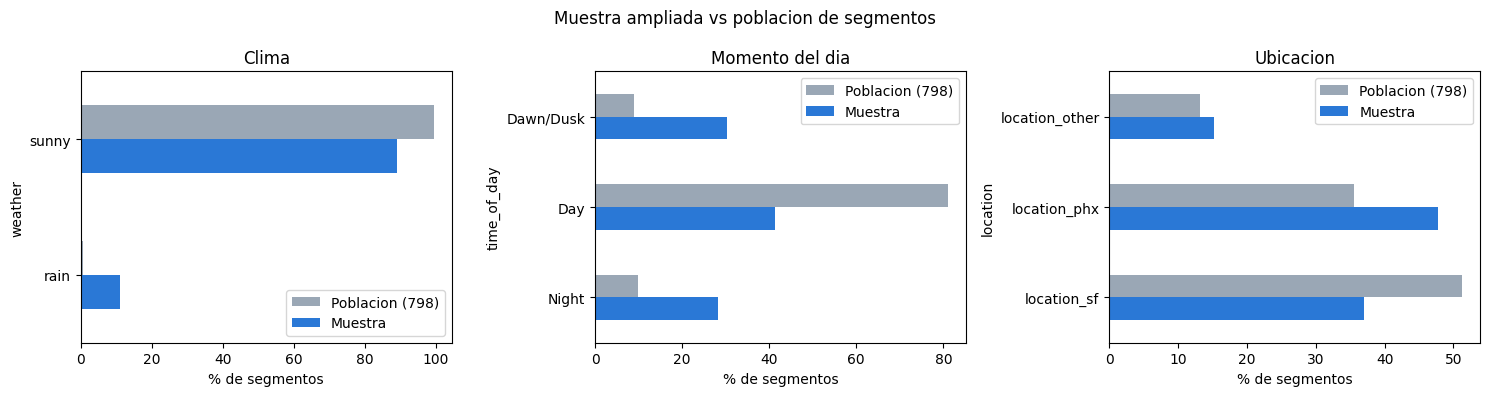

Lluvia en la muestra: 10.9% de los segmentos (poblacion: 0.6%) -> sobrerrepresentada a proposito; las metricas globales NO representan la poblacion real.


In [ ]:
import matplotlib.pyplot as plt


def distribucion(df, col):
    return (df[col].value_counts(normalize=True) * 100).round(1)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes, ["weather", "time_of_day", "location"], ["Clima", "Momento del dia", "Ubicacion"]):
    comp = pd.DataFrame({"Poblacion (798)": distribucion(tabla, col), "Muestra": distribucion(manifiesto, col)}).fillna(0)
    comp.plot.barh(ax=ax, color=["#9aa7b5", "#2a78d6"])
    ax.set_title(titulo)
    ax.set_xlabel("% de segmentos")
    ax.invert_yaxis()
fig.suptitle("Muestra ampliada vs poblacion de segmentos")
fig.tight_layout()
plt.show()

print(f"Lluvia en la muestra: {(manifiesto['weather'] == 'rain').mean() * 100:.1f}% de los segmentos "
      f"(poblacion: {(tabla['weather'] == 'rain').mean() * 100:.1f}%) -> sobrerrepresentada a proposito; "
      "las metricas globales NO representan la poblacion real.")

In [ ]:
# Presencia de clases vulnerables (conteos tomados de stats, sobre toda la muestra)
def pct_clase(df, clase):
    return df[clase].sum() / df["n_detecciones"].sum() * 100


presencia = pd.DataFrame({
    "poblacion (%)": {c: pct_clase(tabla, c) for c in TIPOS.values()},
    "muestra (%)": {c: pct_clase(manifiesto, c) for c in TIPOS.values()},
}).round(2)
print(presencia)
print(f"\nCYCLIST absolutos en la muestra: {int(manifiesto['CYCLIST'].sum()):,}")

            poblacion (%)  muestra (%)
VEHICLE             49.50        46.06
PEDESTRIAN          23.10        26.69
SIGN                26.85        26.70
CYCLIST              0.55         0.55

CYCLIST absolutos en la muestra: 2,756


In [ ]:
# Tasa del target por condicion, solo en segmentos supervisados (anticipa si Day vs Night es evaluable)
sup = manifiesto[manifiesto["uso"] == "supervisado"]

por_condicion = sup.groupby(["weather", "time_of_day"]).agg(
    segmentos=("segment_id", "count"),
    detecciones=("lidar_filas", "sum"),
    positivos=("positivos", "sum"),
)
por_condicion["pct_positivos"] = (por_condicion["positivos"] / por_condicion["detecciones"] * 100).round(2)
print(por_condicion)

print("\nHeterogeneidad entre segmentos (% de positivos por segmento):")
print(sup["pct_positivos"].describe().round(2).to_string())
total_pos, total_det = sup["positivos"].sum(), sup["lidar_filas"].sum()
print(f"\nTasa global de positivos en la muestra supervisada: {total_pos / total_det * 100:.2f}% "
      f"({int(total_pos):,} de {int(total_det):,})")

                     segmentos  detecciones  positivos  pct_positivos
weather time_of_day                                                  
sunny   Dawn/Dusk           11       114962      12720          11.06
        Day                 18       214696      34460          16.05
        Night               12       159955      18410          11.51

Heterogeneidad entre segmentos (% de positivos por segmento):
count    41.00
mean     11.33
std       7.00
min       2.61
25%       6.32
50%       8.86
75%      15.24
max      31.98

Tasa global de positivos en la muestra supervisada: 13.40% (65,590 de 489,613)


In [ ]:
# Densidad de etiquetas de la muestra supervisada (criterio de calidad aplicado en la seccion 5)
print(sup[["pos_por_frame_etiq", "tasa_frames_etiq"]].describe().round(1).to_string())
print("\nMediana de la tasa en frames etiquetados, por momento del dia:")
print(sup.groupby("time_of_day")["tasa_frames_etiq"].median().round(1).to_string())
print("\nFrames con etiquetas / frames totales por segmento (los frames sin ningun positivo se filtran en el pipeline):")
cobertura_frames = (sup["frames_etiquetados"] / sup["n_frames"] * 100).round(0)
print(cobertura_frames.describe().round(0).to_string())

       pos_por_frame_etiq  tasa_frames_etiq
count                41.0              41.0
mean                  8.6              13.4
std                   7.6               6.5
min                   1.2               5.6
25%                   2.5               8.0
50%                   4.1              11.8
75%                  15.5              15.9
max                  25.4              32.0

Mediana de la tasa en frames etiquetados, por momento del dia:
time_of_day
Dawn/Dusk    11.3
Day          13.9
Night        10.2

Frames con etiquetas / frames totales por segmento (los frames sin ningun positivo se filtran en el pipeline):
count     41.0
mean      82.0
std       24.0
min       27.0
25%       69.0
50%       95.0
75%      100.0
max      100.0


In [ ]:
# Control de consistencia: n_detecciones (calculado desde stats) vs filas reales de lidar_box
control = manifiesto.assign(dif_pct=(manifiesto["lidar_filas"] - manifiesto["n_detecciones"]) / manifiesto["n_detecciones"] * 100)
print(control["dif_pct"].describe().round(2).to_string())
print("\nSi la diferencia es ~0%, el filtro por n_detecciones de la seccion 5 era confiable;")
print("si es sistematica, n_detecciones de stats es solo una aproximacion de orden de magnitud.")

count    46.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0

Si la diferencia es ~0%, el filtro por n_detecciones de la seccion 5 era confiable;
si es sistematica, n_detecciones de stats es solo una aproximacion de orden de magnitud.


## Sección 7 — Exportación

Se generan:

- **`segmentos_ep2.csv`**: la lista final con su uso, estrato y métricas.
- **`registro_verificacion_ep2.csv`**: todos los candidatos evaluados, con el
  motivo de cada descarte y su densidad de etiquetas (evidencia para el README).
- **`diagnostico_lluvia_ep2.csv`**: la tabla de los 5 segmentos `rain`.
- **`parametros_segmentos_ep2.yml`**: lista lista para pegar en
  `conf/base/parameters_ingesta_waymo.yml` (**adaptar las claves** a la
  estructura que ya tiene ese archivo).
- **`waymo_ep2_segmentos.tar.gz`**: `lidar_box` y asociaciones con la misma
  estructura de carpetas del proyecto.

In [ ]:
import yaml

manifiesto.to_csv(f"{RUTA_META}/segmentos_ep2.csv", index=False)
registro.to_csv(f"{RUTA_META}/registro_verificacion_ep2.csv", index=False)
diagnostico_lluvia.to_csv(f"{RUTA_META}/diagnostico_lluvia_ep2.csv", index=False)

parametros = {
    "segmentos_ep2": {
        "semilla_muestreo": SEMILLA,
        "segmentos_supervisado": sorted(manifiesto.loc[manifiesto["uso"] == "supervisado", "segment_id"]),
        "segmentos_solo_clustering": sorted(manifiesto.loc[manifiesto["uso"] == "solo_clustering", "segment_id"]),
        "segmentos_lluvia_con_etiquetas_confiables": sorted(
            manifiesto.loc[(manifiesto["uso"] == "supervisado") & (manifiesto["weather"] == "rain"), "segment_id"]
        ),
    }
}
with open(f"{RUTA_META}/parametros_segmentos_ep2.yml", "w") as f:
    yaml.safe_dump(parametros, f, sort_keys=False, default_flow_style=False)

print(open(f"{RUTA_META}/parametros_segmentos_ep2.yml").read())

segmentos_ep2:
  semilla_muestreo: 42
  segmentos_supervisado:
  - '10023947602400723454_1120_000_1140_000'
  - '10206293520369375008_2796_800_2816_800'
  - '10212406498497081993_5300_000_5320_000'
  - '10241508783381919015_2889_360_2909_360'
  - '10444454289801298640_4360_000_4380_000'
  - '10724020115992582208_7660_400_7680_400'
  - '10964956617027590844_1584_680_1604_680'
  - '12174529769287588121_3848_440_3868_440'
  - '13005562150845909564_3141_360_3161_360'
  - '13238419657658219864_4630_850_4650_850'
  - '14143054494855609923_4529_100_4549_100'
  - '14358192009676582448_3396_400_3416_400'
  - '14753089714893635383_873_600_893_600'
  - '14766384747691229841_6315_730_6335_730'
  - '15882343134097151256_4820_000_4840_000'
  - '16153607877566142572_2262_000_2282_000'
  - '16473613811052081539_1060_000_1080_000'
  - '16735938448970076374_1126_430_1146_430'
  - '18136695827203527782_2860_000_2880_000'
  - '18244334282518155052_2360_000_2380_000'
  - '1988987616835805847_3500_000_3520_

In [ ]:
# Verificar que las carpetas finales contienen exactamente lo esperado antes de empaquetar
n_lidar = len(glob.glob(f"{RUTA_LIDAR}/*.parquet"))
n_asoc = len(glob.glob(f"{RUTA_ASOC}/*.parquet"))
esperado_lidar = len(manifiesto)
esperado_asoc = int((manifiesto["uso"] == "supervisado").sum())
print(f"lidar_box:    {n_lidar} archivos (esperado {esperado_lidar})")
print(f"asociaciones: {n_asoc} archivos (esperado {esperado_asoc})")
assert n_lidar == esperado_lidar and n_asoc == esperado_asoc, "Las carpetas finales no coinciden con el manifiesto"

RUTA_TAR = "/content/waymo_ep2_segmentos.tar.gz"
subprocess.run(["tar", "-czf", RUTA_TAR, "-C", RAIZ_SALIDA, "waymo"], check=True)
print(f"Paquete creado: {RUTA_TAR} ({os.path.getsize(RUTA_TAR) / 1e6:.1f} MB)")

lidar_box:    46 archivos (esperado 46)
asociaciones: 41 archivos (esperado 41)
Paquete creado: /content/waymo_ep2_segmentos.tar.gz (34.2 MB)


In [ ]:
from google.colab import files

files.download(RUTA_TAR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cómo integrarlo al proyecto

1. Descomprimir **dentro de `data/01_raw/`** (el `.tar.gz` ya trae la carpeta `waymo/`):

   ```
   tar -xzf waymo_ep2_segmentos.tar.gz -C data/01_raw/
   ```

   Quedan `data/01_raw/waymo/lidar_box/`, `data/01_raw/waymo/camera_to_lidar_box_association/`
   y `data/01_raw/waymo/metadatos_ep2/`. Los 4 segmentos de EP1 ya estaban: se sobrescriben con el mismo contenido.
2. **Copiar a una carpeta que sí se versione** (fuera de `data/01_raw/waymo/`, que está en `.gitignore`)
   `segmentos_ep2.csv`, `registro_verificacion_ep2.csv` y `diagnostico_lluvia_ep2.csv`, para citarlos en el README.
3. Pasar la lista de `parametros_segmentos_ep2.yml` a `conf/base/parameters_ingesta_waymo.yml`.
4. En el pipeline de Kedro, **filtrar los frames sin ningún positivo** dentro de los segmentos
   aceptados (en varios segmentos las etiquetas empiezan a mitad del segmento) y reportar cuántas filas se descartan.
5. Actualizar el README:
   - sección 4 (volumen de datos) y sección 9 (lista de segmentos a descargar);
   - criterio de muestreo y tabla de reemplazos;
   - **matiz de la sección 7** sobre la tasa de positivos en lluvia, según el diagnóstico de la sección 4 de este notebook;
   - KPI de equidad (`Day` vs `Night`) y decisión de no usar `weather` como predictor.
6. Revisar que las cifras del README coincidan con las de este notebook (la conclusión del 00 cita 26,4 % y 1,3 % de
   positivos, mientras que la sección 7 del README cita 32,4 % y 2,4 %: **unificar la fuente** antes de entregar).